# Prova Prática — Ciência de Dados com Python

**Nome:** marcelo eduardo cardoso bastos  **Data:** 23/10/26

## Instruções
1. Baixe o arquivo **vendas_loja.csv** e faça upload no Google Colab (ícone de pasta 📁 na barra lateral).
2. Resolva as **10 questões** nas células indicadas, escrevendo seu código.
3. O notebook deve rodar do início ao fim sem erros (use **Runtime → Run all** antes de entregar).
4. Cada questão vale **1,0 ponto**.

## Dataset: vendas_loja.csv
Registros de vendas de uma loja de eletrônicos, com as colunas:
`produto`, `categoria`, `preco`, `quantidade`, `vendedor`, `regiao`, `mes`

> ⚠️ Atenção: o dataset contém **valores ausentes e linhas duplicadas de propósito** — você vai precisar tratá-los nas questões 4 e 5!


In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Questão 1 — Importação e exploração (1,0 pt)
Importe o arquivo `vendas_loja.csv` e mostre:
- as 5 primeiras linhas (`head`)
- o tamanho do dataset (`shape`)
- as informações gerais (`info`)

In [68]:
# Q1 - seu código aqui
df = pd.read_csv('vendas_loja.csv')

print("Primeiras linhas:")
print(df.head())

print("\nDimensões:")
print(df.shape)

print("\nInformações:")
print(df.info())

Primeiras linhas:
        produto    categoria  preco  quantidade vendedor regiao  mes
0  Caixa de Som        Áudio  110.0        10.0    Carla  Leste  Abr
1       Monitor  Informática  900.0        10.0    Carla  Oeste  Abr
2     Cabo HDMI   Acessórios   30.0         3.0    Diego    Sul  Fev
3        Webcam  Informática  150.0         7.0      Ana  Norte  Mar
4  Caixa de Som        Áudio  110.0         1.0    Diego  Oeste  Abr

Dimensões:
(122, 7)

Informações:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   produto     122 non-null    object 
 1   categoria   122 non-null    object 
 2   preco       118 non-null    float64
 3   quantidade  116 non-null    float64
 4   vendedor    122 non-null    object 
 5   regiao      122 non-null    object 
 6   mes         122 non-null    object 
dtypes: float64(2), object(5)
memory usage: 6.8+ KB
None


## Questão 2 — Explorando com describe (1,0 pt)
Mostre as estatísticas das colunas numéricas com `describe()` e escreva **uma frase** interpretando qual é a média de `preco` do dataset.

In [69]:
# Q2 - seu código aqui
print(df.describe())

média = df["preco"].mean()
máximo = df ["preco"].max()
mínimo = df["preco"].min()

print("Preço médio", media)
print("Preço máximo", máximo)
print("Preço mínimo", mínimo)

print(f"O preço médio é R$ {média:.2f}")
print(f"O maior preço é R$ {mínimo:.2f}")
print(f"O menor preço é R$ {máximo:.2f}")

            preco  quantidade
count  118.000000  116.000000
mean   175.805085    5.267241
std    239.386654    2.979226
min     25.000000    1.000000
25%     40.000000    3.000000
50%    110.000000    5.000000
75%    150.000000    8.000000
max    900.000000   10.000000
Preço médio 175.8050847457627
Preço máximo 900.0
Preço mínimo 25.0
O preço médio é R$ 175.81
O maior preço é R$ 25.00
O menor preço é R$ 900.00


## Questão 3 — NumPy (1,0 pt)
Transforme a coluna `preco` em um array NumPy e calcule e imprima:
- a média
- o maior preço
- o menor preço
- a quantidade de preços registrados (`size`)

In [70]:
# Q3 - seu código aqui
precos = df["preco"].to_numpy()

print("Média:", np.mean(precos))
print("Máximo:", np.max(precos))
print("Mínimo:", np.min(precos))
print("quantidade de preços:", np.size(precos))

Média: nan
Máximo: nan
Mínimo: nan
quantidade de preços: 122


## Questão 4 — Valores ausentes (1,0 pt)
a) Conte quantos valores ausentes existem em **cada coluna**.
b) Preencha os ausentes de `preco` com a **média** da coluna e os de `quantidade` com o valor **0**.
c) Mostre de novo a contagem de ausentes para provar que não sobrou nenhum.
> Justifique em uma frase: por que preencher `quantidade` com 0 e não com a média?

In [71]:
# Q4 - seu código aqui
print("Valores ausentes antes:")
print(df.isnull().sum())

df["preco"] = df["preco"].fillna(df["preco"].mean())

df["quantidade"] = df["quantidade"].fillna(0)

colunas_texto = ["produto", "categoria", "vendedor"]

for coluna in colunas_texto:
    df[coluna] = df[coluna].fillna("Não informado")

print("Valores ausentes depois:")
print(df.isnull().sum())

Valores ausentes antes:
produto       0
categoria     0
preco         4
quantidade    6
vendedor      0
regiao        0
mes           0
dtype: int64
Valores ausentes depois:
produto       0
categoria     0
preco         0
quantidade    0
vendedor      0
regiao        0
mes           0
dtype: int64


## Questão 5 — Duplicados (1,0 pt)
Verifique quantas linhas duplicadas existem no DataFrame e remova-as, mantendo a primeira ocorrência. Mostre o `shape` antes e depois.

In [72]:
# Q5 - seu código aqui
print("Shape antes:", df.shape)
print("Linhas duplicadas:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape depois:", df.shape)

Shape antes: (122, 7)
Linhas duplicadas: 3
Shape depois: (119, 7)


## Questão 6 — Criando coluna calculada (1,0 pt)
Crie a coluna `total`, que deve ser `preco` × `quantidade` (valor total de cada venda). Mostre o DataFrame com as colunas `produto`, `preco`, `quantidade` e `total`.

In [73]:
# Q6 - seu código aqui
df['total'] = df['preco'] * df['quantidade']

print (df[['produto', 'preco', 'quantidade', 'total']])

          produto       preco  quantidade        total
0    Caixa de Som  110.000000        10.0  1100.000000
1         Monitor  900.000000        10.0  9000.000000
2       Cabo HDMI   30.000000         3.0    90.000000
3          Webcam  150.000000         7.0  1050.000000
4    Caixa de Som  110.000000         1.0   110.000000
..            ...         ...         ...          ...
115        Webcam  150.000000         5.0   750.000000
116    HD Externo  350.000000         7.0  2450.000000
117  Caixa de Som  110.000000         9.0   990.000000
118  Caixa de Som  110.000000         9.0   990.000000
119     Pen Drive  175.805085         3.0   527.415254

[119 rows x 4 columns]


## Questão 7 — Filtros com condição (1,0 pt)
Filtre e mostre apenas as vendas cujo `total` seja **maior ou igual a 500**. Quantas vendas são essas?

In [74]:
# Q7 - seu código aqui
vendas_500 = df[df['total'] >= 500]

print(vendas_500)
print("Quantidade de vendas:", len(vendas_500))

          produto      categoria       preco  quantidade vendedor regiao  mes  \
0    Caixa de Som          Áudio  110.000000        10.0    Carla  Leste  Abr   
1         Monitor    Informática  900.000000        10.0    Carla  Oeste  Abr   
3          Webcam    Informática  150.000000         7.0      Ana  Norte  Mar   
5      HD Externo  Armazenamento  350.000000         4.0    Carla  Oeste  Jan   
7    Caixa de Som          Áudio  110.000000         5.0    Diego  Leste  Mai   
9          Webcam    Informática  150.000000         7.0    Carla  Leste  Mar   
10        Monitor    Informática  900.000000         4.0      Ana  Oeste  Mai   
15         Webcam    Informática  150.000000        10.0    Bruno  Oeste  Fev   
16        Teclado    Informática  120.000000         9.0    Bruno    Sul  Mar   
20         Webcam    Informática  150.000000        10.0    Diego  Oeste  Abr   
22     HD Externo  Armazenamento  350.000000         9.0    Diego  Leste  Fev   
26     HD Externo  Armazenam

## Questão 8 — Filtro com duas condições (1,0 pt)
Filtre e mostre as vendas da **região 'Sul'** com **quantidade maior que 5**. Use o operador `&` e não esqueça dos parênteses!
> Escreva o filtro na forma: `df[(condição1) & (condição2)]`

In [75]:
# Q7
vendas_500 = df[df["total"] >= 500]

print(vendas_500)
print("Quantidade de vendas:", len(vendas_500))

          produto      categoria       preco  quantidade vendedor regiao  mes  \
0    Caixa de Som          Áudio  110.000000        10.0    Carla  Leste  Abr   
1         Monitor    Informática  900.000000        10.0    Carla  Oeste  Abr   
3          Webcam    Informática  150.000000         7.0      Ana  Norte  Mar   
5      HD Externo  Armazenamento  350.000000         4.0    Carla  Oeste  Jan   
7    Caixa de Som          Áudio  110.000000         5.0    Diego  Leste  Mai   
9          Webcam    Informática  150.000000         7.0    Carla  Leste  Mar   
10        Monitor    Informática  900.000000         4.0      Ana  Oeste  Mai   
15         Webcam    Informática  150.000000        10.0    Bruno  Oeste  Fev   
16        Teclado    Informática  120.000000         9.0    Bruno    Sul  Mar   
20         Webcam    Informática  150.000000        10.0    Diego  Oeste  Abr   
22     HD Externo  Armazenamento  350.000000         9.0    Diego  Leste  Fev   
26     HD Externo  Armazenam

## Questão 9 — Agrupamento com groupby (1,0 pt)
a) Use `groupby` para mostrar o **total vendido por categoria** (soma da coluna `total`).
b) Monte um resumo com `.agg()` mostrando, por categoria: soma das vendas, ticket médio e quantidade de vendas (use `reset_index()`).
c) Escreva **uma frase**: qual categoria vendeu mais?

In [76]:
# Q9
resumo = df.groupby("categoria").agg(
    soma_vendas=("total", "sum"),
    ticket_medio=("total", "mean"),
    quantidade_vendas=("total", "count")
).reset_index()

print(resumo)

print("Categoria que mais vendeu:", resumo.loc[resumo["soma_vendas"].idxmax(), "categoria"])

       categoria   soma_vendas  ticket_medio  quantidade_vendas
0     Acessórios   6858.050847    185.352726                 37
1  Armazenamento  21350.000000   1779.166667                 12
2    Informática  59470.000000   1415.952381                 42
3          Áudio  16814.491525    600.517554                 28
Categoria que mais vendeu: Informática


## Questão 10 — Visualização (1,0 pt)
Crie **dois gráficos** e escreva uma frase interpretando cada um:
1. **Matplotlib**: gráfico de barras com o total vendido por categoria (com `title`, `xlabel` e `ylabel`).
2. **Seaborn**: `boxplot` da coluna `total` por `regiao` — existe alguma região com vendas fora da curva?

<function matplotlib.pyplot.show(close=None, block=None)>

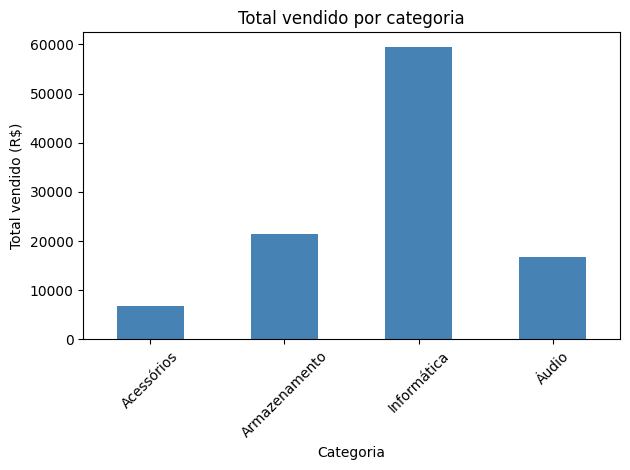

In [77]:
# Q10 - gráfico 1 (Matplotlib)
total_categoria = df.groupby('categoria')['total'].sum()

total_categoria.plot(kind='bar', color='steelblue')

plt.title('Total vendido por categoria')
plt.xlabel('Categoria')
plt.ylabel('Total vendido (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show

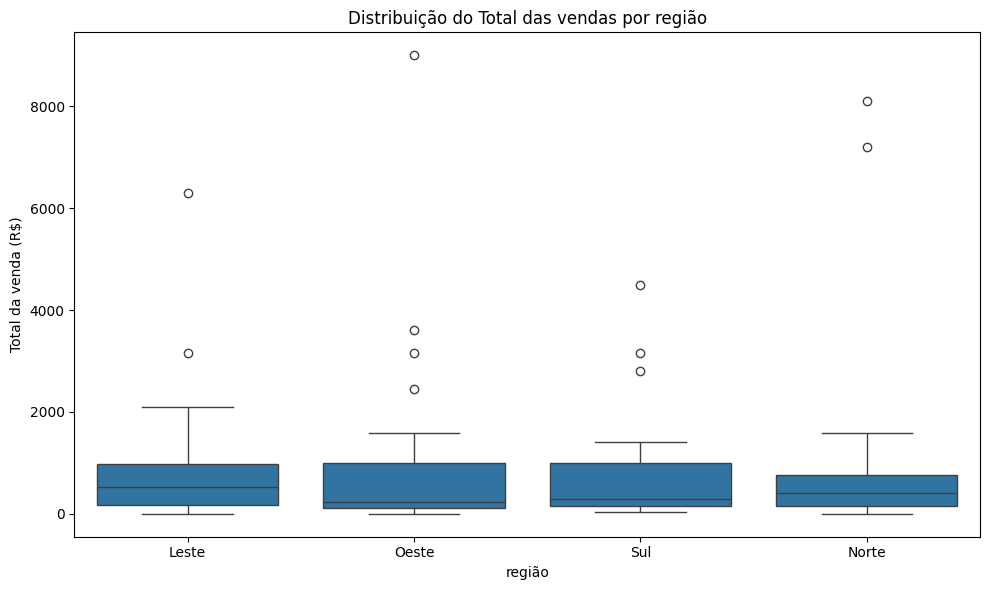

In [78]:
# Q10 - gráfico 2 (Seaborn)
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='regiao', y='total')

plt.title("Distribuição do Total das vendas por região")
plt.xlabel('região')
plt.ylabel('Total da venda (R$)')
plt.tight_layout()
plt.show()

---
## Entrega
1. Rode tudo: **Runtime → Run all** e confira que não há erros.
2. Baixe o notebook: **File → Download → Download .ipynb**.
3. Envie o arquivo `.ipynb` pelo link indicado pelo professor.

**Boa prova! 🚀**